In [1]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#nltk.download('punkt_tab')
#nltk.download('stopwords')

def preprocess_text(text): #converts a string into a list of words excluding stopwords and non alphabetic
    stop_words = set(stopwords.words('english'))
    tokens = word_tokenize(text.lower())
    tokens = [word for word in tokens if word.isalpha() and word not in stop_words]
    return tokens

df = pd.read_csv('potential-talents.csv')

In [2]:
print(df["job_title"])

0      2019 C.T. Bauer College of Business Graduate (...
1      Native English Teacher at EPIK (English Progra...
2                  Aspiring Human Resources Professional
3                 People Development Coordinator at Ryan
4        Advisory Board Member at Celal Bayar University
                             ...                        
99     Aspiring Human Resources Manager | Graduating ...
100                Human Resources Generalist at Loparex
101     Business Intelligence and Analytics at Travelers
102                       Always set them up for Success
103     Director Of Administration at Excellence Logging
Name: job_title, Length: 104, dtype: str


In [3]:

#sentences = [
#    "The quick brown fox jumps over the lazy dog.",
#    "Artificial intelligence is transforming the world we live in.",
#    "Deep learning techniques have greatly improved image recognition.",
#    "Natural language processing allows computers to understand human language.",
#    "Data science combines statistics, computer science, and domain knowledge.",
#    "The weather is nice today, perfect for a walk in the park.",
#    "Cats are often seen as independent and curious creatures.",
#    "The stock market fluctuates based on various economic indicators.",
#    "Exploring new cuisines can be an exciting culinary adventure.",
#    "Machine learning algorithms can learn from data and make predictions.",
#    "The king and the queen rule the kingdom.",
#    "A cat is a common household pet."
#    "a man and a woman married each other"
#]
preprocessed_sentences = [preprocess_text(sentence) for sentence in df['job_title']] #performing defined function on each element

model = Word2Vec(sentences=preprocessed_sentences, vector_size=100, window=5, min_count=1, workers=4, sg=1)

model.save("word2vec_candidates.model") #saves to binary file

In [4]:
#assert False

In [5]:
#print(preprocessed_sentences)

In [6]:
try:
    similarity_fox_dog = model.wv.similarity('human', 'resources')
    print(f"Similarity between 'human' and 'resources': {similarity_fox_dog:.4f}")
except KeyError as e:
    print(f"KeyError: {e}")

try:
    similar_words_language = model.wv.most_similar('aspiring', topn=3)
    print("Most similar words to 'aspiring':", similar_words_language)
except KeyError as e:
    print(f"KeyError: {e}")

try:
    analogy_result = model.wv.most_similar(positive=['seeking', 'aspiring'], negative=['hr'], topn=1)
    print("Analogy result for 'seeking + aspiring - hr':", analogy_result)
except KeyError as e:
    print(f"KeyError: {e}")

Similarity between 'human' and 'resources': 0.0520
Most similar words to 'aspiring': [('administration', 0.3735910952091217), ('officer', 0.2204980105161667), ('member', 0.20917019248008728)]
Analogy result for 'seeking + aspiring - hr': [('administration', 0.37027209997177124)]


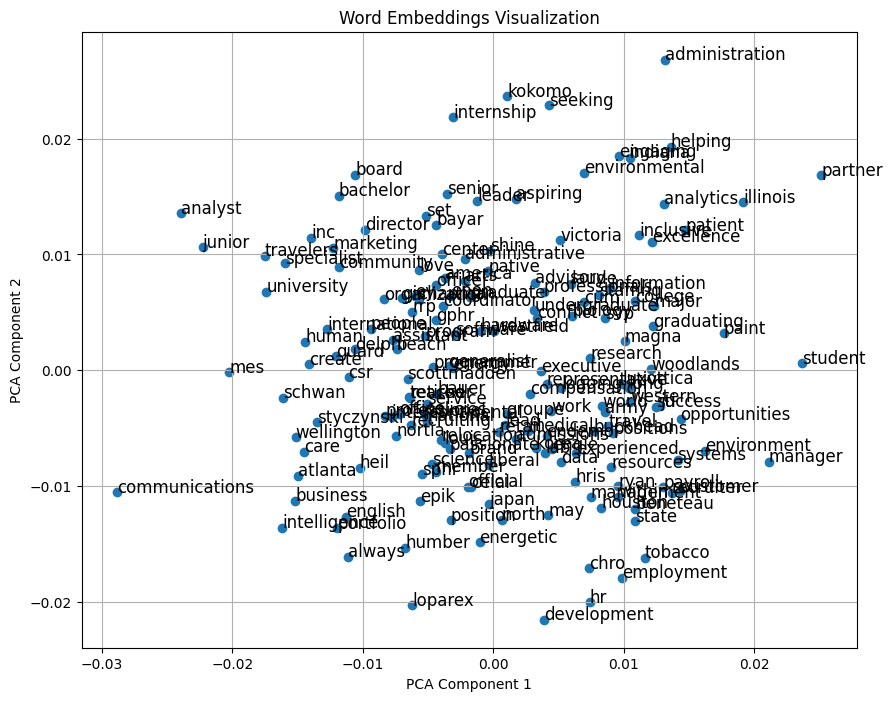

In [7]:
word_vectors = model.wv[model.wv.index_to_key]  #method on model with method on model
pca = PCA(n_components=2)  #what is this?
result = pca.fit_transform(word_vectors) #method on pca with word_vectors as input

plt.figure(figsize=(10, 8)) #plt is an import; it looks like this is just graphical
plt.scatter(result[:, 0], result[:, 1])

words = list(model.wv.index_to_key) #words is the list of words stored in model
for i, word in enumerate(words):
    plt.annotate(word, xy=(result[i, 0], result[i, 1]), fontsize=12)

plt.title("Word Embeddings Visualization")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid()
plt.show()

In [8]:
print(words)

['human', 'resources', 'aspiring', 'professional', 'student', 'seeking', 'generalist', 'college', 'specialist', 'university', 'business', 'coordinator', 'english', 'manager', 'humber', 'laude', 'cum', 'magna', 'graduate', 'bauer', 'senior', 'hr', 'ryan', 'development', 'people', 'management', 'korea', 'program', 'epik', 'teacher', 'native', 'opportunities', 'atlanta', 'buckhead', 'intercontinental', 'sphr', 'gphr', 'energy', 'woodlands', 'houston', 'engie', 'officer', 'csr', 'communications', 'marketing', 'chro', 'svp', 'chapman', 'positions', 'hris', 'bayar', 'celal', 'member', 'board', 'advisory', 'major', 'position', 'director', 'internship', 'leader', 'systems', 'information', 'america', 'north', 'staffing', 'retail', 'logging', 'excellence', 'administration', 'success', 'set', 'always', 'travelers', 'analytics', 'intelligence', 'loparex', 'louis', 'may', 'graduating', 'paint', 'hardware', 'delphi', 'kokomo', 'indiana', 'state', 'westfield', 'relocation', 'travel', 'open', 'beach',